In [177]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

In [178]:
# Load the data

In [179]:
#Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data2/Data.csv')
Data = Data.iloc[:, 8:]

In [180]:
Data

,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,0.00,0.00,0.00,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,14.52,0.00,14.52,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,14.52,14.52,14.52,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,25.71,14.52,25.71,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,14.34,14.34,25.71,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,27.34,27.34,115.84,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,91.25,27.34,91.25,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,85.24,85.24,91.25,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,42.76,42.76,85.24,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [181]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10332 entries, 0 to 10331
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   MotionToPhotonLatency  10332 non-null  float64
 1   minMtpLatency          10332 non-null  float64
 2   maxMtpLatency          10332 non-null  float64
 3   avgMtpLatency          10332 non-null  float64
 4   StdDev mtpLatency      10332 non-null  float64
 5   mtpEntropy             10332 non-null  float64
 6   currentRotation.x      10332 non-null  float64
 7   currentRotation.y      10332 non-null  float64
 8   currentRotation.z      10332 non-null  float64
 9   currentRotation.w      10332 non-null  float64
 10  pitch                  10332 non-null  float64
 11  yaw                    10332 non-null  float64
 12  roll                   10332 non-null  float64
dtypes: float64(13)
memory usage: 1.0 MB


In [182]:
Data.head(10)

,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,0.00,0.00,0.00,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,14.52,0.00,14.52,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,14.52,14.52,14.52,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,25.71,14.52,25.71,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,14.34,14.34,25.71,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
5,12.84,12.84,14.34,14.32,4.70,0.14,0.34,-0.10,-0.14,0.93,36.49,339.33,336.17
6,14.41,12.84,14.41,14.37,4.71,0.15,0.33,-0.11,-0.14,0.93,36.22,339.10,336.32
7,14.69,14.41,14.69,14.53,4.70,0.19,0.33,-0.11,-0.14,0.93,35.86,338.75,336.44
8,14.34,14.34,14.69,14.45,0.65,0.18,0.33,-0.11,-0.13,0.93,35.46,338.31,336.46
9,12.37,12.37,14.34,13.60,0.94,0.20,0.33,-0.12,-0.13,0.93,35.04,337.75,336.37


In [183]:
Data.shape

(10332, 13)

In [184]:
# create new column "Labels" based on "FPS"
Data["Labels"] = Data["MotionToPhotonLatency"].apply(lambda x: 0 if x <= 20 else 1)

In [185]:
Data.iloc[4990 : 5050]

,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll,Labels
4990,14.21,14.21,14.21,15.28,0.25,0.57,0.03,0.09,-0.06,0.99,4.30,10.42,353.05,0
4991,28.43,14.21,28.43,15.30,5.72,0.42,0.03,0.09,-0.06,0.99,4.30,10.43,353.22,1
4992,14.05,14.05,28.43,15.30,5.71,0.41,0.03,0.09,-0.06,0.99,4.28,10.40,353.42,0
4993,12.80,12.80,14.05,15.29,5.87,0.52,0.03,0.09,-0.06,0.99,4.21,10.34,353.58,0
4994,12.80,12.80,12.80,15.29,6.02,0.64,0.03,0.09,-0.06,0.99,4.18,10.24,353.69,0
4995,27.80,12.80,27.80,15.31,7.32,0.54,0.03,0.09,-0.06,0.99,4.21,10.12,353.78,1
4996,13.73,13.73,27.80,15.31,5.80,0.69,0.03,0.09,-0.06,0.99,4.25,9.99,353.91,0
4997,13.66,13.66,13.73,15.30,5.83,0.72,0.03,0.09,-0.05,0.99,4.26,9.82,354.05,0
4998,14.14,13.66,14.14,15.30,5.70,0.61,0.03,0.09,-0.05,0.99,4.28,9.63,354.16,0
4999,14.02,14.02,14.14,15.30,5.57,0.51,0.03,0.08,-0.05,0.99,4.26,9.40,354.29,0


In [186]:
# Select input features and target variable

In [187]:
X = Data.iloc[:, 0 :]
X.drop(['Labels'], axis=1, inplace=True)

In [188]:
y = Data['Labels']

In [189]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [190]:
#Scale data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [191]:
# Fit a random forest regressor and get the feature importances

In [192]:
rf = RandomForestRegressor(n_estimators=100, random_state=100)
rf.fit(X_train, y_train)

RandomForestRegressor(random_state=100)

In [193]:
print(f'model score on training data: {rf.score(X_train, y_train)}')
print(f'model score on testing data: {rf.score(X_test, y_test)}')

model score on training data: 0.9999357754975856
model score on testing data: 1.0


In [194]:
importances_rf = rf.feature_importances_
indices = np.argsort(importances_rf)[::-1]

In [195]:
# Get feature names
feature_names_rf = X.columns

In [196]:
# Sort features by importance
indices = np.argsort(importances_rf)[::-1]

In [197]:
# Print feature ranking
print("Feature ranking:")
for f in range(X.shape[1]):
    print("%d. feature %d (%f) - %s" % (f + 1, indices[f], importances_rf[indices[f]], feature_names_rf[indices[f]]))

Feature ranking:
1. feature 0 (1.000000) - MotionToPhotonLatency
2. feature 12 (0.000000) - roll
3. feature 11 (0.000000) - yaw
4. feature 10 (0.000000) - pitch
5. feature 9 (0.000000) - currentRotation.w
6. feature 8 (0.000000) - currentRotation.z
7. feature 7 (0.000000) - currentRotation.y
8. feature 6 (0.000000) - currentRotation.x
9. feature 5 (0.000000) - mtpEntropy
10. feature 4 (0.000000) - StdDev mtpLatency
11. feature 3 (0.000000) - avgMtpLatency
12. feature 2 (0.000000) - maxMtpLatency
13. feature 1 (0.000000) - minMtpLatency


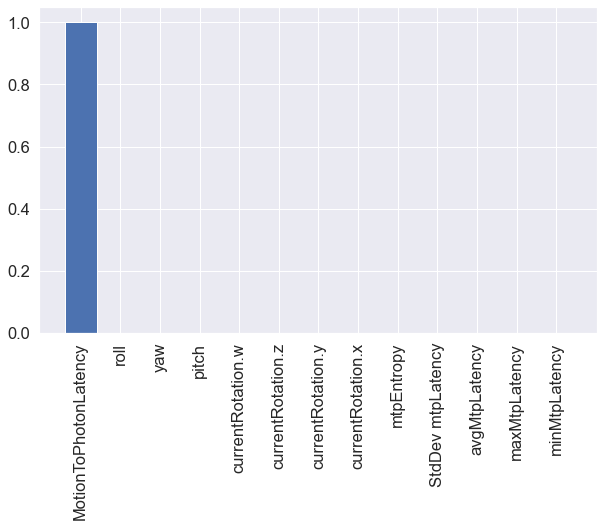

In [198]:
# Plot feature importances
plt.figure(figsize=(10, 6))
plt.bar(range(len(importances_rf)), importances_rf[indices])
plt.xticks(range(len(importances_rf)), feature_names_rf[indices], rotation=90)
plt.show()

In [199]:
# Calculate permutation importances

In [200]:
result = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42)

In [201]:
# Print feature ranking
sorted_idx = result.importances_mean.argsort()[::-1]
for i in sorted_idx:
    print(f"{X.columns[i]:<15} {result.importances_mean[i]:.3f} +/- {result.importances_std[i]:.3f}")

MotionToPhotonLatency 2.008 +/- 0.051
roll            0.000 +/- 0.000
yaw             0.000 +/- 0.000
pitch           0.000 +/- 0.000
currentRotation.w 0.000 +/- 0.000
currentRotation.z 0.000 +/- 0.000
currentRotation.y 0.000 +/- 0.000
currentRotation.x 0.000 +/- 0.000
mtpEntropy      0.000 +/- 0.000
StdDev mtpLatency 0.000 +/- 0.000
avgMtpLatency   0.000 +/- 0.000
maxMtpLatency   0.000 +/- 0.000
minMtpLatency   0.000 +/- 0.000


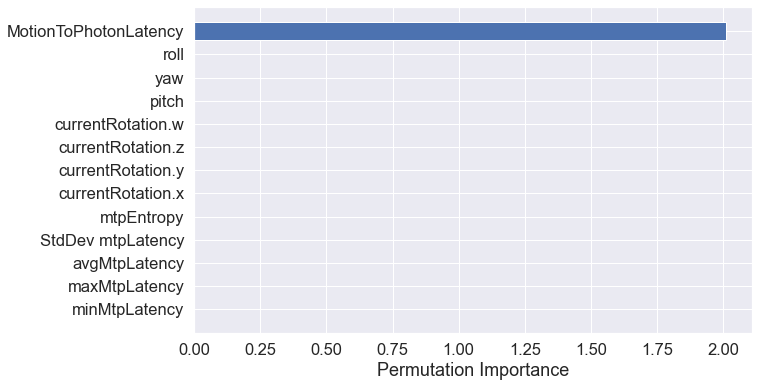

In [202]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [203]:
# Fit a linear regression model

In [204]:
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [205]:
print(f'model score on training data: {lr.score(X_train, y_train)}')
print(f'model score on testing data: {lr.score(X_test, y_test)}')

model score on training data: 0.5498756504806419
model score on testing data: 0.5371089629809191


In [206]:
# Get the coefficient values and feature names

In [207]:
coef_lr = lr.coef_

In [208]:
# Print the feature importance

In [209]:
feature_names_lr = X.columns

In [210]:
# Print the feature importance
print("Feature importance:")
for i in range(len(feature_names_lr)):
    print("%s: %f" % (feature_names_lr[i], abs(coef_lr[i])))

Feature importance:
MotionToPhotonLatency: 0.074455
minMtpLatency: 0.012268
maxMtpLatency: 0.053636
avgMtpLatency: 0.300166
StdDev mtpLatency: 0.051462
mtpEntropy: 0.167336
currentRotation.x: 0.004846
currentRotation.y: 0.053966
currentRotation.z: 0.032749
currentRotation.w: 0.018253
pitch: 0.035293
yaw: 0.006284
roll: 0.025221


In [211]:
# Print the feature importance in order of highest to lowest absolute coefficient values
print("Feature importance:")
sorted_indices = np.argsort(abs(coef_lr))[::-1]
for i in sorted_indices:
    print("%s: %f" % (feature_names_lr[i], abs(coef_lr[i])))

Feature importance:
avgMtpLatency: 0.300166
mtpEntropy: 0.167336
MotionToPhotonLatency: 0.074455
currentRotation.y: 0.053966
maxMtpLatency: 0.053636
StdDev mtpLatency: 0.051462
pitch: 0.035293
currentRotation.z: 0.032749
roll: 0.025221
currentRotation.w: 0.018253
minMtpLatency: 0.012268
yaw: 0.006284
currentRotation.x: 0.004846


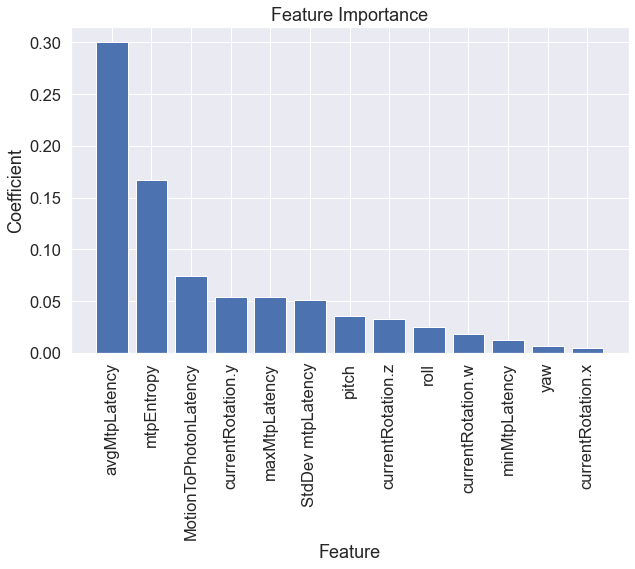

In [212]:
# Plot feature importance in order of highest to lowest absolute coefficient values
sorted_indices = np.argsort(abs(coef_lr))[::-1]
sorted_features = [feature_names_lr[i] for i in sorted_indices]
sorted_coefficients = [abs(coef_lr[i]) for i in sorted_indices]

plt.figure(figsize=(10, 6))
plt.bar(sorted_features, sorted_coefficients)
plt.xticks(rotation=90)
plt.xlabel('Feature')
plt.ylabel('Coefficient')
plt.title('Feature Importance')
plt.show()

In [213]:
# Calculate permutation importances

In [214]:
result = permutation_importance(lr, X_test, y_test, n_repeats=10, random_state=42)

In [215]:
# Print permutation importances
print("Permutation importances:")
for i in result.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names_lr[i], result.importances_mean[i]))

Permutation importances:
avgMtpLatency: 0.766628
mtpEntropy: 0.232571
MotionToPhotonLatency: 0.037374
currentRotation.y: 0.026650
StdDev mtpLatency: 0.015277
maxMtpLatency: 0.011842
pitch: 0.009346
currentRotation.z: 0.008218
roll: 0.005365
currentRotation.w: 0.002247
currentRotation.x: 0.000397
yaw: 0.000080
minMtpLatency: -0.000151


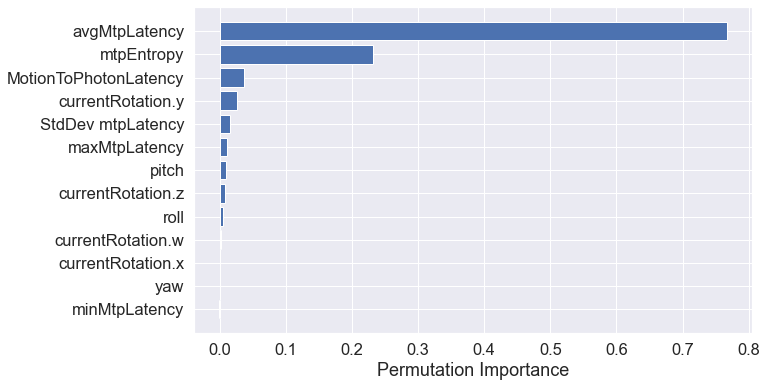

In [216]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [217]:
# Fit a Logistic Regression model

In [218]:
lor = LogisticRegression(max_iter= 1000)
lor.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [219]:
print(f'model score on training data: {lor.score(X_train, y_train)}')
print(f'model score on testing data: {lor.score(X_test, y_test)}')

model score on training data: 0.9921355111917726
model score on testing data: 0.9937106918238994


In [220]:
# Get the coefficient values and feature names

In [221]:
coef_lor = lor.coef_[0]
feature_names_lor = X.columns

In [222]:
# Print the feature names and their absolute coefficient values in descending order
for name, value in sorted(zip(feature_names_lor, abs(coef_lor)), key=lambda x: -x[1]):
    print("%s: %f" % (name, value))

MotionToPhotonLatency: 17.855576
minMtpLatency: 4.952787
maxMtpLatency: 0.910464
avgMtpLatency: 0.596118
currentRotation.y: 0.465481
mtpEntropy: 0.117437
roll: 0.108333
currentRotation.z: 0.104447
StdDev mtpLatency: 0.050518
currentRotation.x: 0.048082
currentRotation.w: 0.026399
pitch: 0.015150
yaw: 0.014403


In [223]:
# Sort features by absolute coefficient value
sorted_features = [name for name, value in sorted(zip(feature_names_lor, abs(coef_lor)), key=lambda x: -x[1])]
sorted_coefs = [value for name, value in sorted(zip(feature_names_lor, abs(coef_lor)), key=lambda x: -x[1])]

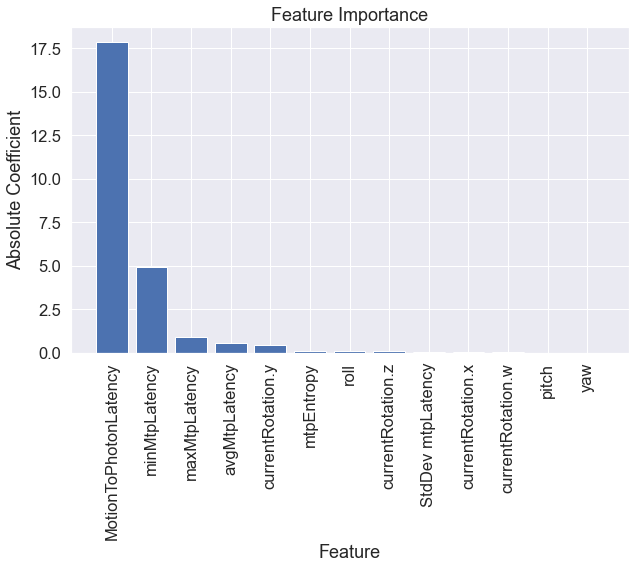

In [224]:
# Create bar plot of feature importance
plt.figure(figsize=(10, 6))
plt.bar(sorted_features, sorted_coefs)
plt.xticks(rotation=90)
plt.xlabel('Feature')
plt.ylabel('Absolute Coefficient')
plt.title('Feature Importance')
plt.show()

In [225]:
# Calculate permutation importances

In [226]:
result = permutation_importance(lor, X_test, y_test, n_repeats=10, random_state=42)

In [227]:
# Print permutation importances
print("Permutation importances:")
for i in result.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names_lor[i], result.importances_mean[i]))

Permutation importances:
MotionToPhotonLatency: 0.341171
minMtpLatency: 0.066376
maxMtpLatency: 0.001064
currentRotation.y: 0.000726
roll: 0.000145
yaw: 0.000000
pitch: 0.000000
currentRotation.w: 0.000000
currentRotation.x: 0.000000
mtpEntropy: 0.000000
StdDev mtpLatency: 0.000000
currentRotation.z: -0.000145
avgMtpLatency: -0.000339


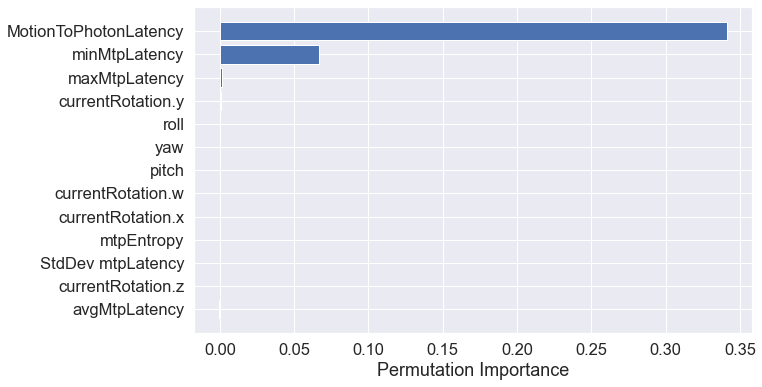

In [228]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [229]:
#Decision tree-based 

In [230]:
# Train a decision tree classifier on the original dataset

In [231]:
clf = DecisionTreeClassifier()
clf.fit(X_train, y_train)

DecisionTreeClassifier()

In [232]:
print(f'model score on training data: {clf.score(X_train, y_train)}')
print(f'model score on testing data: {clf.score(X_test, y_test)}')

model score on training data: 1.0
model score on testing data: 1.0


In [233]:
# Plot the feature importance

In [234]:
importance_clf = clf.feature_importances_
feature_names_clf = X.columns

In [235]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': importance_clf})

In [236]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                  Feature  Importance
0   MotionToPhotonLatency         1.0
1           minMtpLatency         0.0
2           maxMtpLatency         0.0
3           avgMtpLatency         0.0
4       StdDev mtpLatency         0.0
5              mtpEntropy         0.0
6       currentRotation.x         0.0
7       currentRotation.y         0.0
8       currentRotation.z         0.0
9       currentRotation.w         0.0
10                  pitch         0.0
11                    yaw         0.0
12                   roll         0.0


In [237]:
sorted_idx = importance_clf.argsort()

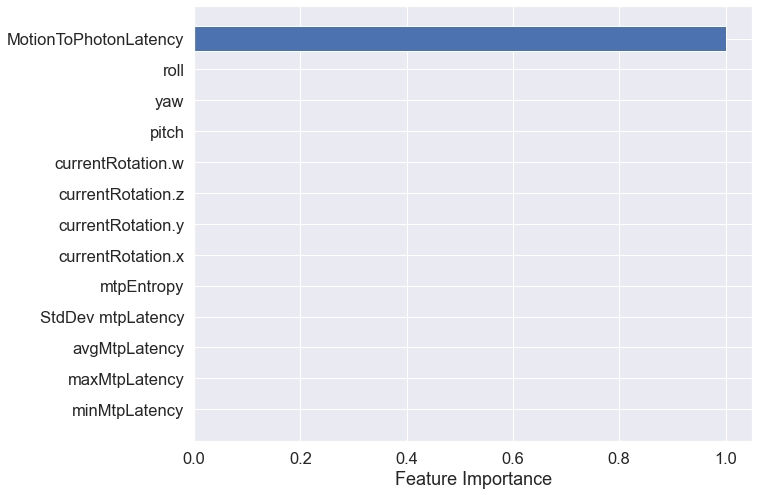

In [238]:
plt.figure(figsize = (10, 8))
plt.barh(range(len(sorted_idx)), importance_clf[sorted_idx])
plt.yticks(range(len(sorted_idx)), [feature_names_clf[i] for i in sorted_idx])
plt.xlabel('Feature Importance')
plt.show()

In [239]:
# Calculate permutation importance
perm_importance = permutation_importance(clf, X_train, y_train, n_repeats=10, random_state=42)

In [240]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance.importances_mean})

In [241]:
feature_importance

,Feature,Importance
0,MotionToPhotonLatency,0.47078
1,minMtpLatency,0.00000
2,maxMtpLatency,0.00000
3,avgMtpLatency,0.00000
4,StdDev mtpLatency,0.00000
5,mtpEntropy,0.00000
6,currentRotation.x,0.00000
7,currentRotation.y,0.00000
8,currentRotation.z,0.00000
9,currentRotation.w,0.00000


In [242]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                  Feature  Importance
0   MotionToPhotonLatency     0.47078
1           minMtpLatency     0.00000
2           maxMtpLatency     0.00000
3           avgMtpLatency     0.00000
4       StdDev mtpLatency     0.00000
5              mtpEntropy     0.00000
6       currentRotation.x     0.00000
7       currentRotation.y     0.00000
8       currentRotation.z     0.00000
9       currentRotation.w     0.00000
10                  pitch     0.00000
11                    yaw     0.00000
12                   roll     0.00000


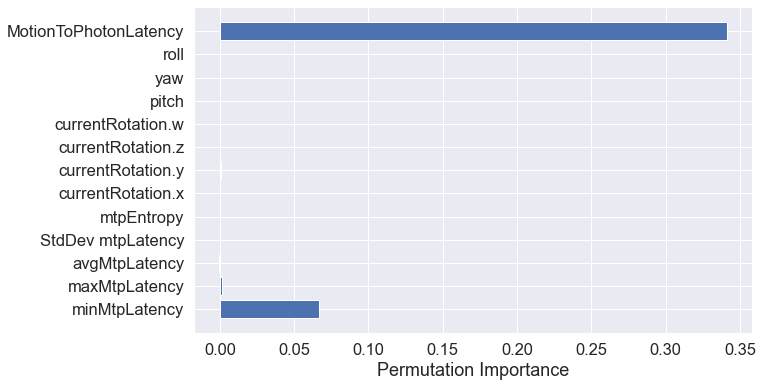

In [243]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [244]:
#Lasso regression

In [245]:
# Train a Lasso regression model on the original dataset

In [246]:
Lasso = Lasso(alpha=0.1)
Lasso.fit(X_train, y_train)

Lasso(alpha=0.1)

In [247]:
print(f'model score on training data: {Lasso.score(X_train, y_train)}')
print(f'model score on testing data: {Lasso.score(X_test, y_test)}')

model score on training data: 0.43854390402483
model score on testing data: 0.4261762697644671


In [248]:
# Get the absolute value of the regression coefficients

In [249]:
Lasso_abs = abs(Lasso.coef_)

In [250]:
Lasso_abs

array([0.        , 0.        , 0.        , 0.20290376, 0.        ,
       0.07011172, 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        ])

In [251]:
# Create a DataFrame to store the feature importance scores and names

In [252]:
feature_importance_Lasso = pd.DataFrame({'Feature_names': X.columns, 'Importance':Lasso_abs})

In [253]:
# Sort the features by importance and print the ranked list

In [254]:
feature_importance_Lasso = feature_importance_Lasso.sort_values('Importance', ascending=False)

In [255]:
feature_importance_Lasso

,Feature_names,Importance
3,avgMtpLatency,0.202904
5,mtpEntropy,0.070112
0,MotionToPhotonLatency,0.000000
1,minMtpLatency,0.000000
2,maxMtpLatency,0.000000
4,StdDev mtpLatency,0.000000
6,currentRotation.x,0.000000
7,currentRotation.y,0.000000
8,currentRotation.z,0.000000
9,currentRotation.w,0.000000


In [256]:
# Create a barplot of the feature importance scores>

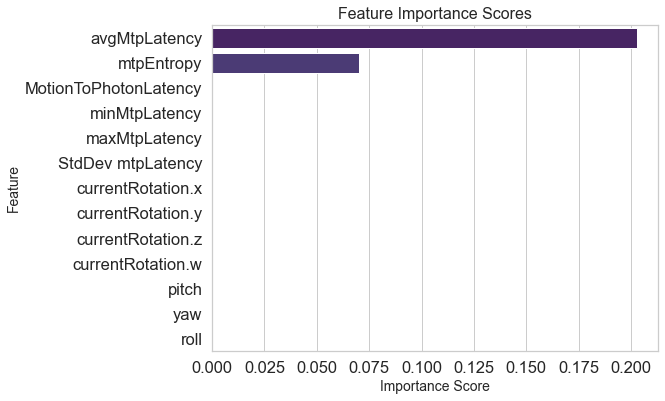

In [257]:
plt.figure(figsize=(8, 6))
sns.set_style('whitegrid')
sns.barplot(x='Importance', y='Feature_names', data=feature_importance_Lasso, palette='viridis')
plt.xlabel('Importance Score', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.title('Feature Importance Scores', fontsize=16)
plt.show()

In [258]:
# Calculate permutation importance
perm_importance_Lasso = permutation_importance(Lasso, X_train, y_train, n_repeats=10, random_state=42)

In [259]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance.importances_mean})

In [260]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                  Feature  Importance
0   MotionToPhotonLatency     0.47078
1           minMtpLatency     0.00000
2           maxMtpLatency     0.00000
3           avgMtpLatency     0.00000
4       StdDev mtpLatency     0.00000
5              mtpEntropy     0.00000
6       currentRotation.x     0.00000
7       currentRotation.y     0.00000
8       currentRotation.z     0.00000
9       currentRotation.w     0.00000
10                  pitch     0.00000
11                    yaw     0.00000
12                   roll     0.00000


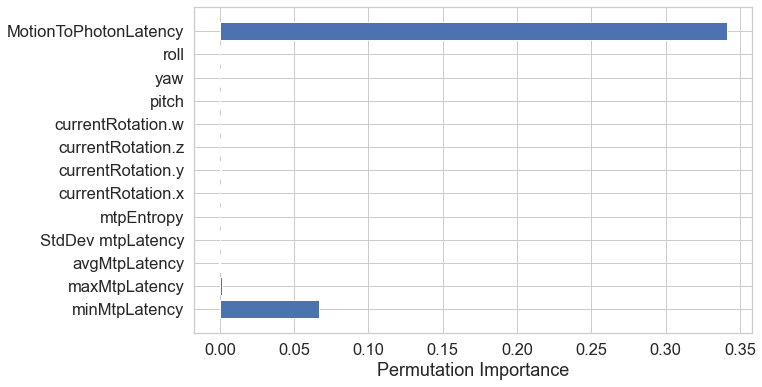

In [261]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [262]:
#XGBClassifier

In [263]:
from xgboost import XGBClassifier

In [264]:
# Instantiate XGBClassifier with default hyperparameters

In [265]:
xgb = XGBClassifier()
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              n_estimators=100, n_jobs=None, num_parallel_tree=None,
              predictor=None, random_state=None, ...)

In [266]:
# Use the built-in feature importance method to get feature importance scores
feat_importances_xgb = xgb.feature_importances_

In [267]:
feat_importances_xgb

array([1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)

In [268]:
# Create a dictionary mapping feature names to importance scores
feat_importances_dict = {feat: score for feat, score in zip(X.columns, feat_importances_xgb)}

In [269]:
feat_importances_dict

{'MotionToPhotonLatency': 1.0,
 'minMtpLatency': 0.0,
 'maxMtpLatency': 0.0,
 'avgMtpLatency': 0.0,
 'StdDev mtpLatency': 0.0,
 'mtpEntropy': 0.0,
 'currentRotation.x': 0.0,
 'currentRotation.y': 0.0,
 'currentRotation.z': 0.0,
 'currentRotation.w': 0.0,
 'pitch': 0.0,
 'yaw': 0.0,
 'roll': 0.0}

In [270]:
# Sort the ditionary in descending order of importance score
sorted_feat_importances = sorted(feat_importances_dict.items(), key=lambda x: x[1], reverse=True)

In [271]:
# Print the sorted feature importance scores
for feat, score in sorted_feat_importances:
    print(f'{feat}: {score}')

MotionToPhotonLatency: 1.0
minMtpLatency: 0.0
maxMtpLatency: 0.0
avgMtpLatency: 0.0
StdDev mtpLatency: 0.0
mtpEntropy: 0.0
currentRotation.x: 0.0
currentRotation.y: 0.0
currentRotation.z: 0.0
currentRotation.w: 0.0
pitch: 0.0
yaw: 0.0
roll: 0.0


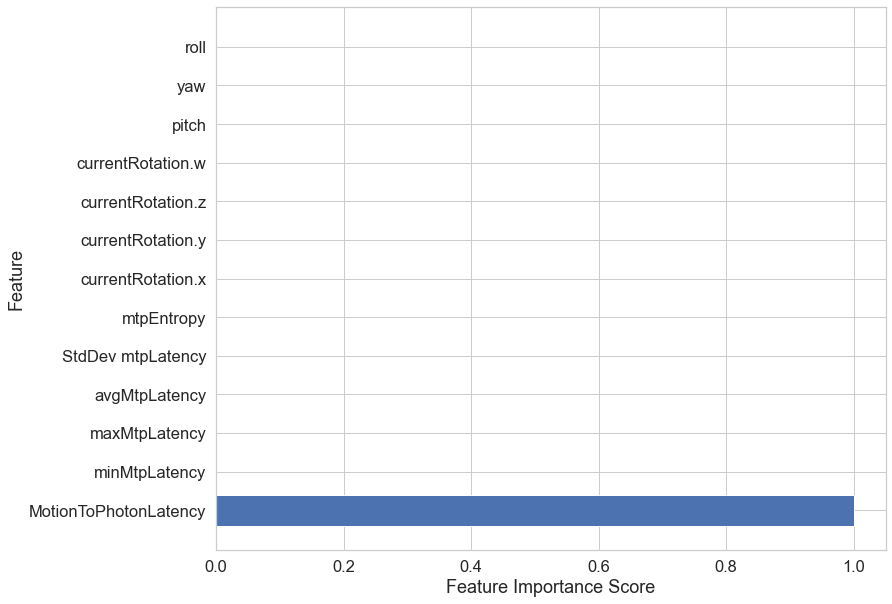

In [272]:
# Plot the feature importance scores as a horizontal bar chart
plt.figure(figsize = (12, 10))
plt.barh(range(len(feat_importances_xgb)), feat_importances_xgb)
plt.yticks(range(len(feat_importances_xgb)), X.columns)
plt.xlabel('Feature Importance Score')
plt.ylabel('Feature')
plt.show()

In [273]:
# Calculate permutation importance
perm_importance_xgb = permutation_importance(xgb, X_train, y_train, n_repeats=10, random_state=42)

In [274]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance_xgb.importances_mean})

In [275]:
feature_importance 

,Feature,Importance
0,MotionToPhotonLatency,0.47078
1,minMtpLatency,0.00000
2,maxMtpLatency,0.00000
3,avgMtpLatency,0.00000
4,StdDev mtpLatency,0.00000
5,mtpEntropy,0.00000
6,currentRotation.x,0.00000
7,currentRotation.y,0.00000
8,currentRotation.z,0.00000
9,currentRotation.w,0.00000


In [276]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                  Feature  Importance
0   MotionToPhotonLatency     0.47078
1           minMtpLatency     0.00000
2           maxMtpLatency     0.00000
3           avgMtpLatency     0.00000
4       StdDev mtpLatency     0.00000
5              mtpEntropy     0.00000
6       currentRotation.x     0.00000
7       currentRotation.y     0.00000
8       currentRotation.z     0.00000
9       currentRotation.w     0.00000
10                  pitch     0.00000
11                    yaw     0.00000
12                   roll     0.00000


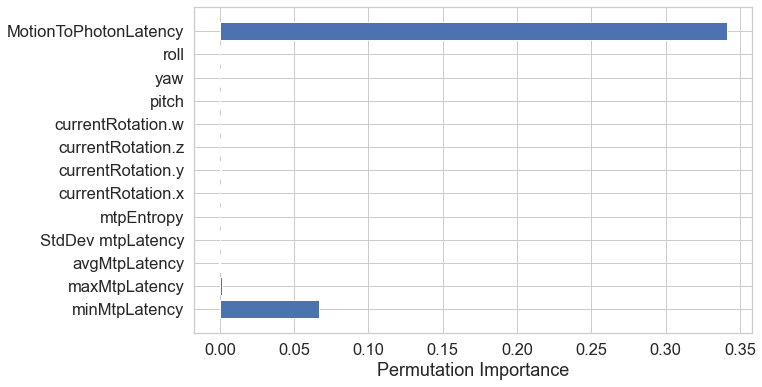

In [277]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance_xgb.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [278]:
#Elastic Net Feature Importance

In [279]:
from sklearn.linear_model import ElasticNetCV

# Create Elastic Net object
enet = ElasticNetCV(cv=5, random_state=0)

# Fit the model on training data
enet.fit(X_train, y_train)

# Extract feature importance from coefficients
feature_importance = abs(enet.coef_)

# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

# Print the feature importance scores
for feature in sorted_features:
    print(feature[0], ": ", feature[1])


avgMtpLatency :  0.36349027200563805
mtpEntropy :  0.20264951502568285
MotionToPhotonLatency :  0.08544811425723747
currentRotation.y :  0.0650795843609427
StdDev mtpLatency :  0.06206898017647496
maxMtpLatency :  0.061770543712084375
pitch :  0.04275120160606682
currentRotation.z :  0.038916218678517404
roll :  0.03050553260922683
currentRotation.w :  0.02193394444161596
minMtpLatency :  0.012153270825365594
yaw :  0.007593240534444163
currentRotation.x :  0.00563958176670269


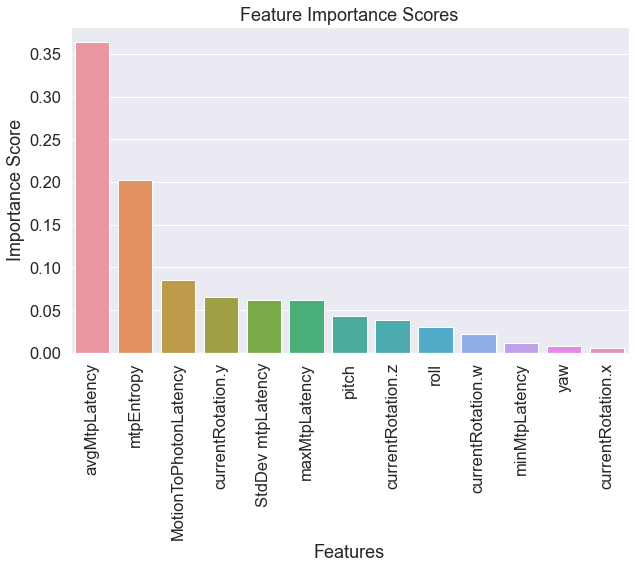

In [280]:
# Create a bar plot of feature importance scores
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
fig, ax = plt.subplots(figsize=(10,6))
sns.barplot(x=[x[0] for x in sorted_features], y=[x[1] for x in sorted_features], ax=ax)
ax.set_title("Feature Importance Scores")
ax.set_xlabel("Features")
ax.set_ylabel("Importance Score")
plt.xticks(rotation=90)
plt.show()

In [281]:
# Calculate permutation importance
perm_importance_enet = permutation_importance(enet, X_train, y_train, n_repeats=10, random_state=42)

In [282]:
# Create a DataFrame to store the feature importance scores and names
feature_importance_enet = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance_enet.importances_mean})
feature_importance_enet

,Feature,Importance
0,MotionToPhotonLatency,0.041139
1,minMtpLatency,0.001002
2,maxMtpLatency,0.022539
3,avgMtpLatency,0.756201
4,StdDev mtpLatency,0.022602
5,mtpEntropy,0.236042
6,currentRotation.x,0.000204
7,currentRotation.y,0.024562
8,currentRotation.z,0.008672
9,currentRotation.w,0.002592


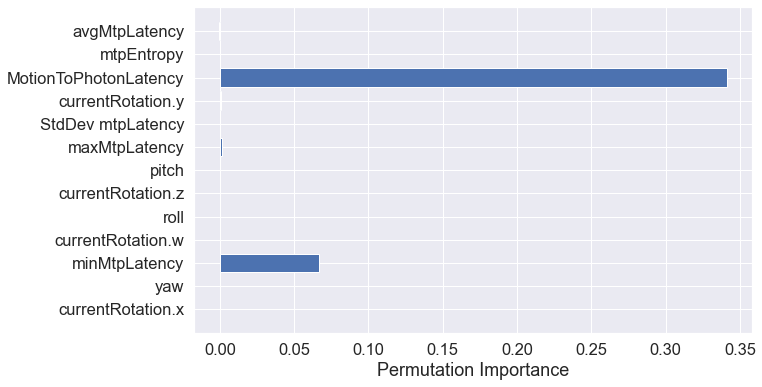

In [283]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance_enet.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [284]:
# Ridge model

In [285]:
ridge = Ridge()
ridge.fit(X_train, y_train)

Ridge()

In [286]:
# Predict on the testing data
y_pred = ridge.predict(X_test)

In [287]:
from sklearn.metrics import mean_squared_error

In [288]:
# Evaluate the model performance on testing data
mse = mean_squared_error(y_test, y_pred)
print("Mean squared error:", mse)

Mean squared error: 0.11045482075974043


In [289]:
# Extract feature importance from coefficients
feature_importance = abs(ridge.coef_)

In [290]:
# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

In [291]:
# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

In [292]:
# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

In [293]:
sorted_features

[('avgMtpLatency', 0.35913087497571483),
 ('mtpEntropy', 0.2002287717719141),
 ('MotionToPhotonLatency', 0.08899806394234627),
 ('currentRotation.y', 0.06458276575506182),
 ('maxMtpLatency', 0.06409042794057868),
 ('StdDev mtpLatency', 0.06156303427396082),
 ('pitch', 0.042241823870151594),
 ('currentRotation.z', 0.039183070110034905),
 ('roll', 0.030183386419092812),
 ('currentRotation.w', 0.02184460541415794),
 ('minMtpLatency', 0.014613538230361564),
 ('yaw', 0.007538651893638784),
 ('currentRotation.x', 0.00580098540298593)]

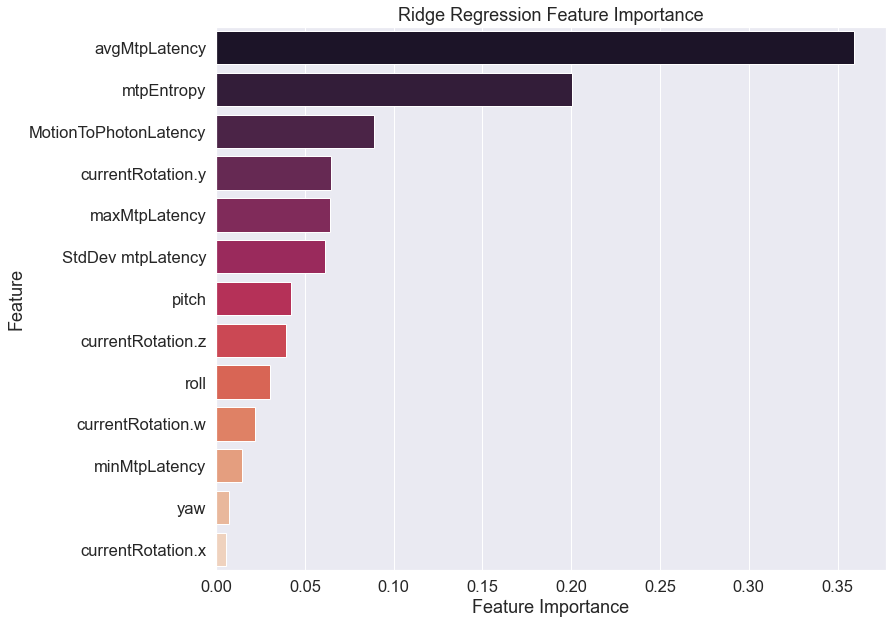

In [294]:
plt.figure(figsize = (12, 10))
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
sns.barplot(x=[x[1] for x in sorted_features], y=[x[0] for x in sorted_features], palette="rocket")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Ridge Regression Feature Importance")
plt.show()

In [295]:
# Calculate permutation importance
perm_importance_ridge = permutation_importance(ridge, X_train, y_train, n_repeats=10, random_state=42)

In [296]:
# Create a DataFrame to store the feature importance scores and names
feature_importance_ridge = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance_enet.importances_mean})
feature_importance_ridge

,Feature,Importance
0,MotionToPhotonLatency,0.041139
1,minMtpLatency,0.001002
2,maxMtpLatency,0.022539
3,avgMtpLatency,0.756201
4,StdDev mtpLatency,0.022602
5,mtpEntropy,0.236042
6,currentRotation.x,0.000204
7,currentRotation.y,0.024562
8,currentRotation.z,0.008672
9,currentRotation.w,0.002592


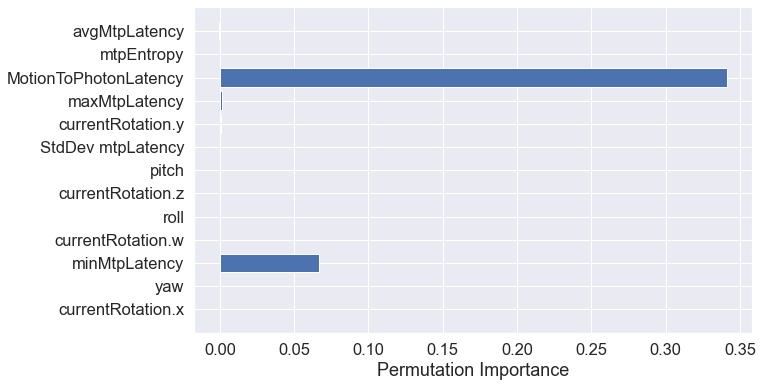

In [297]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance_ridge.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [298]:
#shap

In [299]:
import shap

Permutation explainer: 2068it [05:32,  6.04it/s]                          


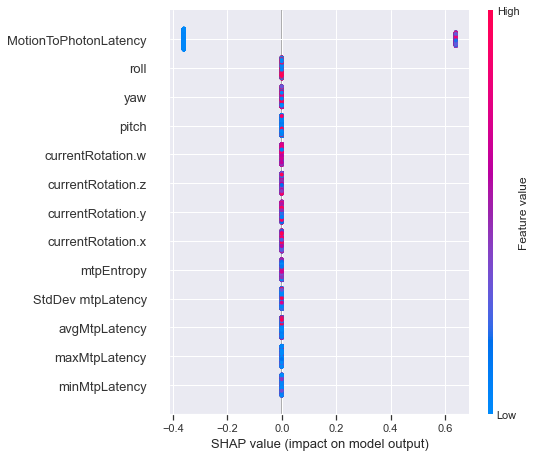

In [300]:
# Train a random forest regressor model
rf = RandomForestRegressor(random_state=100)
rf.fit(X_train, y_train)

# Calculate Shapley value feature importance
explainer = shap.Explainer(rf.predict, X_train)
shap_values = explainer(X_test)
shap.summary_plot(shap_values, X_test, feature_names=X.columns)